In [ ]:
print("My First Data Analysis Project")
print("Using Python")

My First Data Analysis Project
Using Python


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [ ]:
import pandas as pd

data = {
    "Order_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "Product": ["Mobile", "Laptop", "Headphones", "Mobile", "Laptop",
                "Mouse", "Keyboard", "Mobile", "Laptop", "Headphones"],
    "Category": ["Electronics", "Electronics", "Accessories", "Electronics",
                 "Electronics", "Accessories", "Accessories", "Electronics",
                 "Electronics", "Accessories"],
    "Quantity": [2, 1, 3, 1, 2, 4, 2, 3, 1, 2],
    "Price": [15000, 50000, 1000, 15000, 50000, 500, 800, 15000, 50000, 1000]
}

df = pd.DataFrame(data)

df["Sales"] = df["Quantity"] * df["Price"]

print(df)

   Order_ID     Product     Category  Quantity  Price   Sales
0       101      Mobile  Electronics         2  15000   30000
1       102      Laptop  Electronics         1  50000   50000
2       103  Headphones  Accessories         3   1000    3000
3       104      Mobile  Electronics         1  15000   15000
4       105      Laptop  Electronics         2  50000  100000
5       106       Mouse  Accessories         4    500    2000
6       107    Keyboard  Accessories         2    800    1600
7       108      Mobile  Electronics         3  15000   45000
8       109      Laptop  Electronics         1  50000   50000
9       110  Headphones  Accessories         2   1000    2000


In [ ]:
total_sales = df["Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 298600


In [ ]:
product_sales = df.groupby("Product")["Sales"].sum()

print("Product-wise Sales:")
print(product_sales)

Product-wise Sales:
Product
Headphones      5000
Keyboard        1600
Laptop        200000
Mobile         90000
Mouse           2000
Name: Sales, dtype: int64


In [ ]:
highest_product = product_sales.idxmax()
highest_sales = product_sales.max()

print("Highest Selling Product:", highest_product)
print("Total Sales:", highest_sales)


Highest Selling Product: Laptop
Total Sales: 200000


In [ ]:
category_sales = df.groupby("Category")["Sales"].sum()

print("Category-wise Sales:")
print(category_sales)

Category-wise Sales:
Category
Accessories      8600
Electronics    290000
Name: Sales, dtype: int64


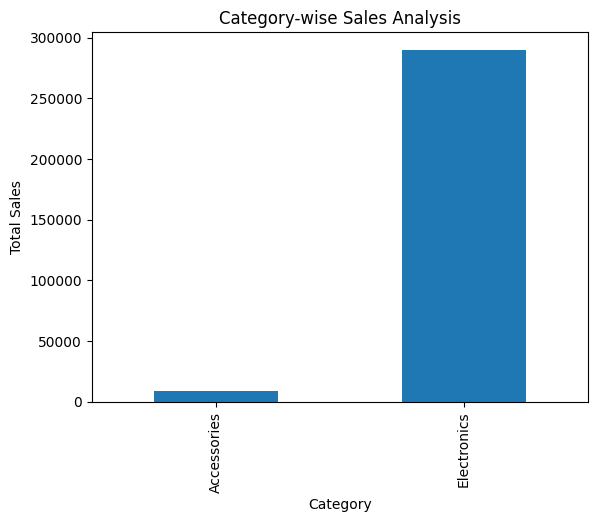

In [ ]:
import matplotlib.pyplot as plt

category_sales.plot(kind="bar")

plt.title("Category-wise Sales Analysis")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

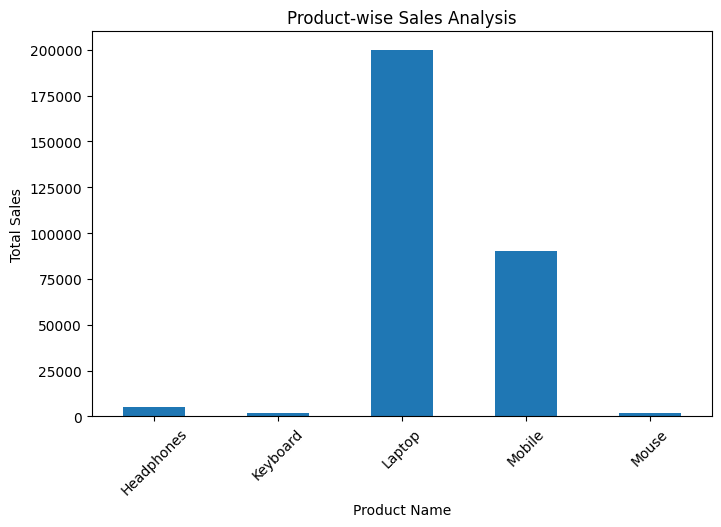

In [ ]:
product_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Product-wise Sales Analysis")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
Order_ID    0
Product     0
Category    0
Quantity    0
Price       0
Sales       0
dtype: int64
Duplicate Records:
0


In [ ]:
# Create a copy of original data
cleaned_df = df.copy()

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# Remove rows with missing values
cleaned_df = cleaned_df.dropna()

print("Data Cleaning Completed!")
print(cleaned_df)

Data Cleaning Completed!
   Order_ID     Product     Category  Quantity  Price   Sales
0       101      Mobile  Electronics         2  15000   30000
1       102      Laptop  Electronics         1  50000   50000
2       103  Headphones  Accessories         3   1000    3000
3       104      Mobile  Electronics         1  15000   15000
4       105      Laptop  Electronics         2  50000  100000
5       106       Mouse  Accessories         4    500    2000
6       107    Keyboard  Accessories         2    800    1600
7       108      Mobile  Electronics         3  15000   45000
8       109      Laptop  Electronics         1  50000   50000
9       110  Headphones  Accessories         2   1000    2000


In [ ]:
df["Order_Date"] = pd.to_datetime([
    "2026-01-05", "2026-01-10",
    "2026-02-05", "2026-02-12",
    "2026-02-20", "2026-03-05",
    "2026-03-10", "2026-03-15",
    "2026-04-05", "2026-04-10"
])

df["Month"] = df["Order_Date"].dt.month_name()

monthly_sales = df.groupby("Month")["Sales"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
April        52000
February    118000
January      80000
March        48600
Name: Sales, dtype: int64


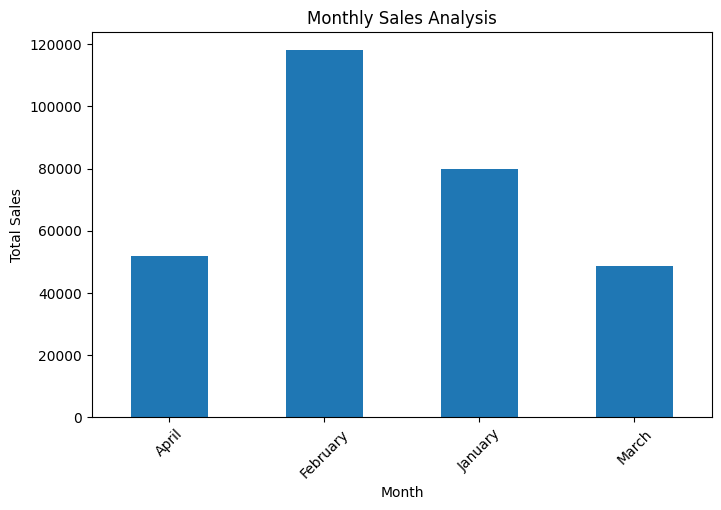

In [ ]:
monthly_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [ ]:
total_orders = df["Order_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_sales = df["Sales"].mean()
total_revenue = df["Sales"].sum()

print("Sales Summary")
print("----------------------")
print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Average Sales:", average_sales)
print("Total Revenue:", total_revenue)

Sales Summary
----------------------
Total Orders: 10
Total Quantity Sold: 21
Average Sales: 29860.0
Total Revenue: 298600


In [ ]:
top_products = product_sales.sort_values(ascending=False).head(3)

print("Top 3 Selling Products:")
print(top_products)

Top 3 Selling Products:
Product
Laptop        200000
Mobile         90000
Headphones      5000
Name: Sales, dtype: int64


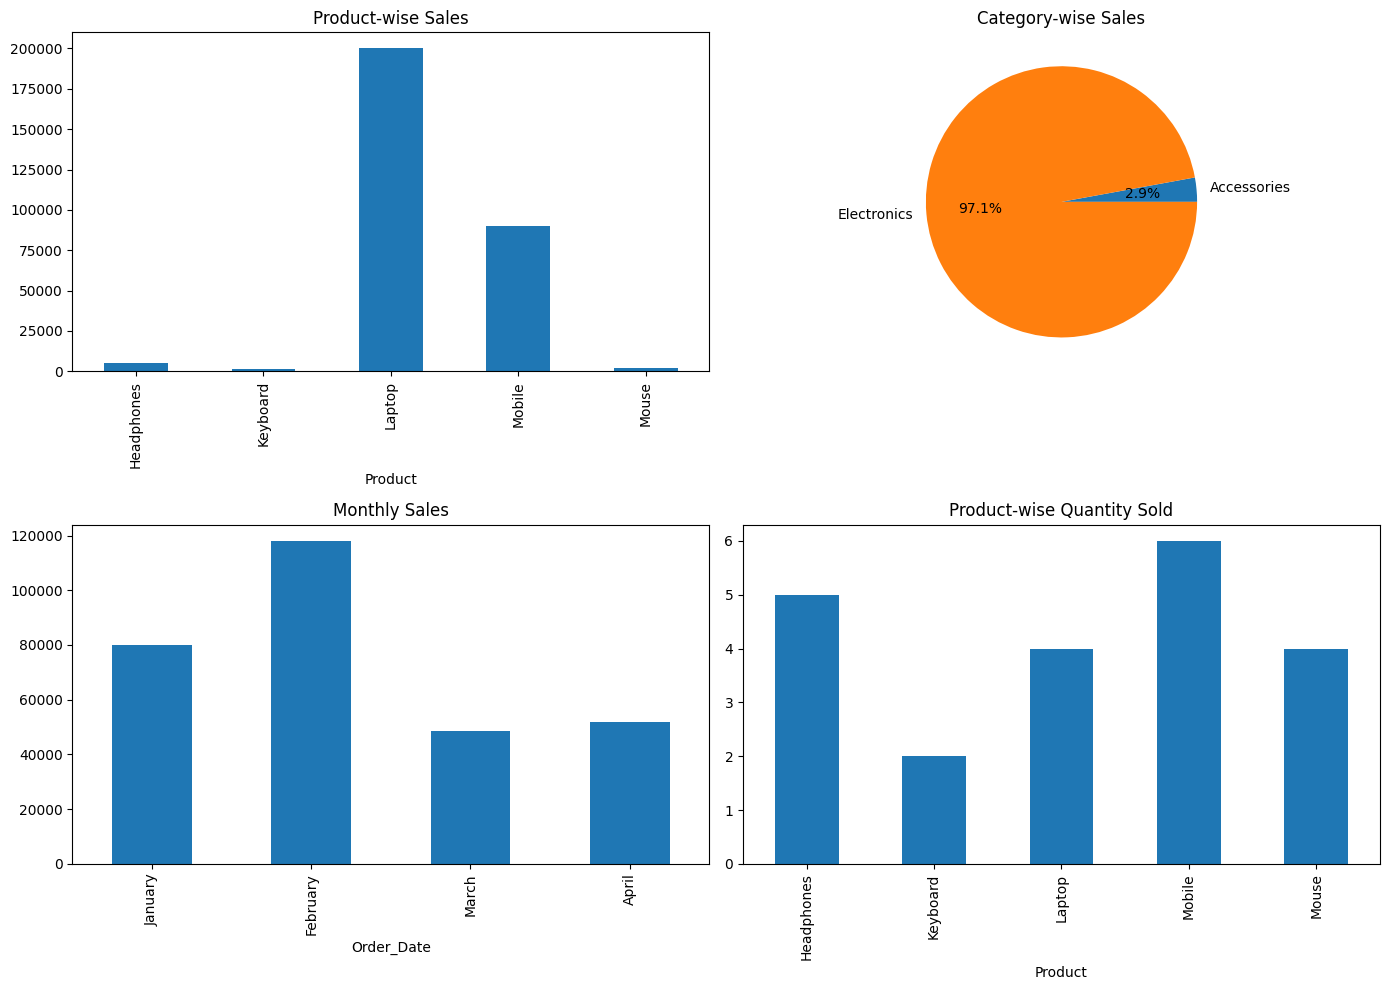

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Product-wise sales
product_sales.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Product-wise Sales")

# Category-wise sales
category_sales.plot(kind="pie", autopct="%1.1f%%", ax=axes[0, 1])
axes[0, 1].set_title("Category-wise Sales")
axes[0, 1].set_ylabel("")

# Monthly sales
monthly_sales = df.groupby(
    df["Order_Date"].dt.month_name(), sort=False
)["Sales"].sum()

monthly_sales.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Monthly Sales")

# Quantity sold
df.groupby("Product")["Quantity"].sum().plot(
    kind="bar", ax=axes[1, 1]
)
axes[1, 1].set_title("Product-wise Quantity Sold")

plt.tight_layout()
plt.show()

In [ ]:
print("========== E-COMMERCE SALES ANALYSIS ==========")

print("1. Total Revenue: ₹", df["Sales"].sum())

print("2. Highest Selling Product:",
      product_sales.idxmax())

print("3. Highest Product Sales: ₹",
      product_sales.max())

print("4. Best Sales Month:",
      monthly_sales.idxmax())

print("5. Total Orders:",
      df["Order_ID"].nunique())

print("6. Total Products:",
      df["Product"].nunique())

print("===============================================")

========== E-COMMERCE SALES ANALYSIS ==========
1. Total Revenue: ₹ 298600
2. Highest Selling Product: Laptop
3. Highest Product Sales: ₹ 200000
4. Best Sales Month: February
5. Total Orders: 10
6. Total Products: 5


In [ ]:
import zipfile

with zipfile.ZipFile("/content/archive.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

print("ZIP file extracted successfully!")

ZIP file extracted successfully!


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'online_retail.csv', 'archive.zip', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv("/content/online_retail.csv", encoding="ISO-8859-1")

print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape:
(541909, 8)

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
print("Total Duplicate Records:")
print(df.duplicated().sum())

Total Duplicate Records:
5268


In [ ]:
df = df.drop_duplicates()

print("Duplicate Records Removed!")
print("Updated Dataset Shape:", df.shape)

Duplicate Records Removed!
Updated Dataset Shape: (536641, 8)


In [ ]:
# Remove returned and invalid sales
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Total revenue
total_revenue = sales_df["Revenue"].sum()

print("Total Revenue:", total_revenue)
print("Total Sales Records:", len(sales_df))

Total Revenue: 10642110.804000001
Total Sales Records: 524878


In [ ]:
top_products = sales_df.groupby("Description")["Quantity"].sum()

top_products = top_products.sort_values(
    ascending=False
).head(10)

print("Top 10 Best-Selling Products:")
print(top_products)

Top 10 Best-Selling Products:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


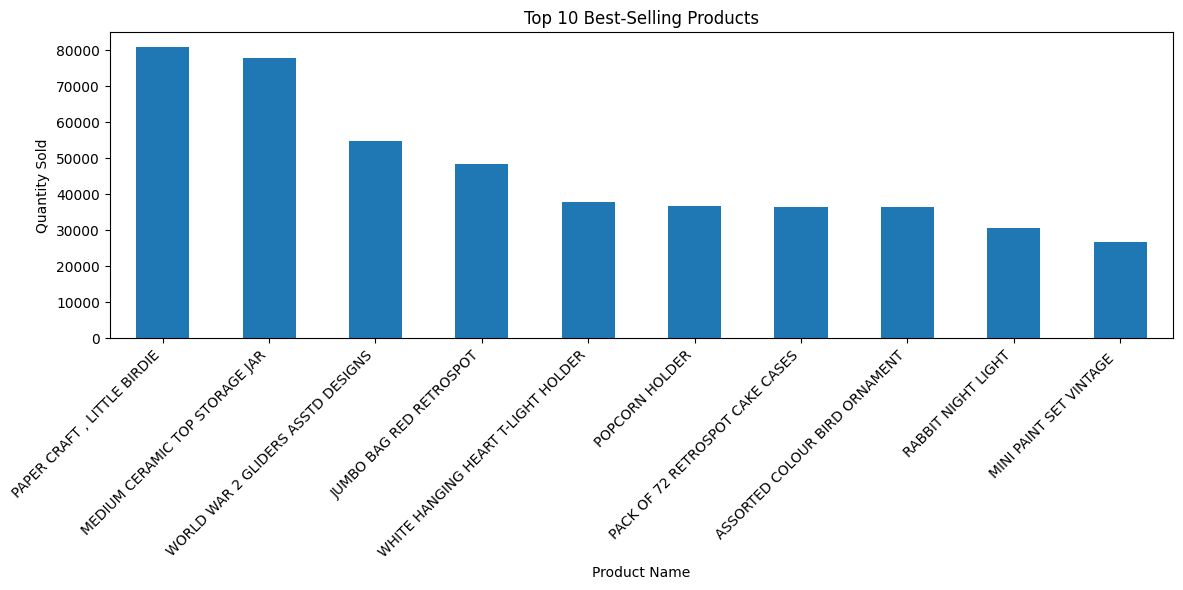

In [ ]:
import matplotlib.pyplot as plt

top_products.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product Name")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
country_sales = sales_df.groupby("Country")["Revenue"].sum()

country_sales = country_sales.sort_values(
    ascending=False
).head(10)

print("Top 10 Countries by Revenue:")
print(country_sales)

Top 10 Countries by Revenue:
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


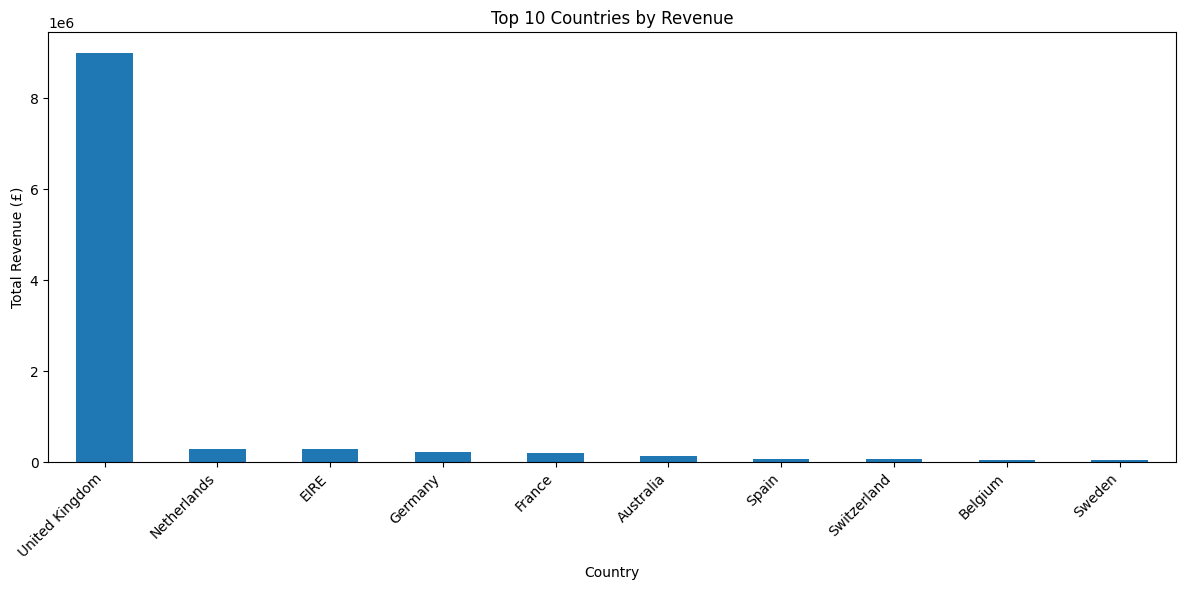

In [ ]:
country_sales.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_sales = sales_df.groupby("Month")["Revenue"].sum()

print("Monthly Sales Analysis:")
print(monthly_sales)

Monthly Sales Analysis:
Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


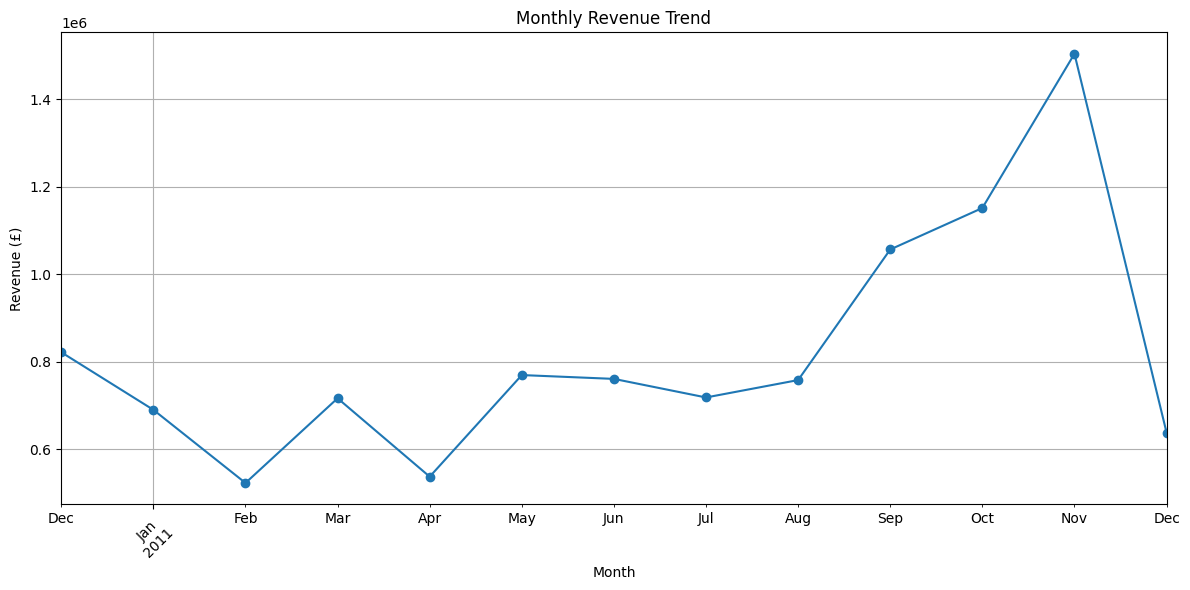

In [ ]:
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
customer_sales = sales_df.dropna(subset=["CustomerID"]).groupby(
    "CustomerID"
)["Revenue"].sum()

top_customers = customer_sales.sort_values(
    ascending=False
).head(10)

print("Top 10 Customers by Revenue:")
print(top_customers)

Top 10 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


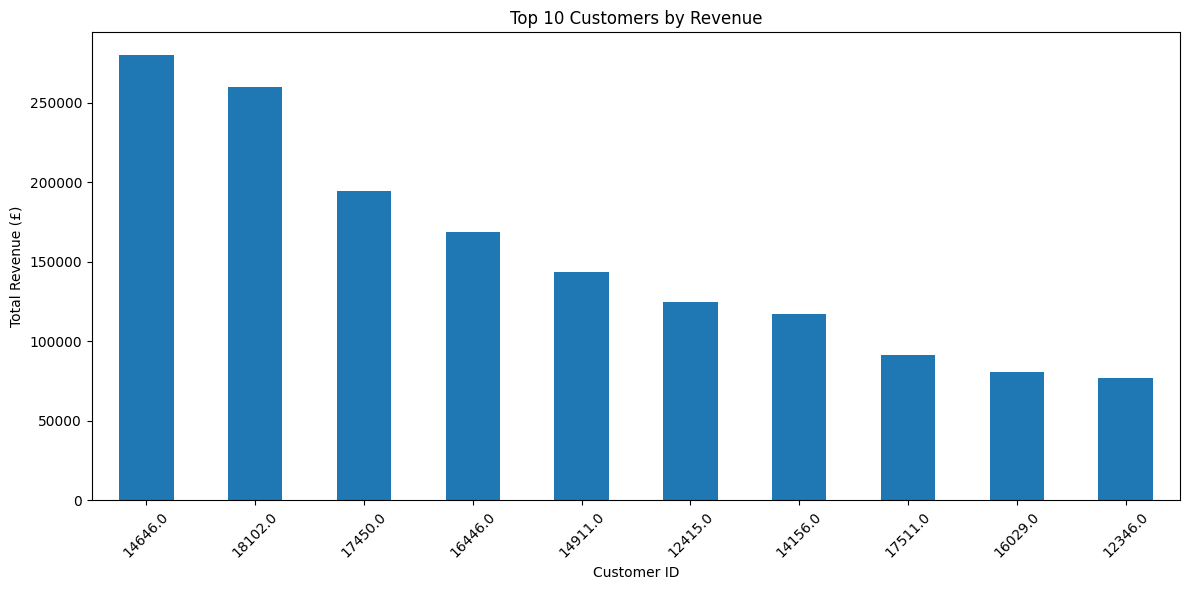

In [ ]:
top_customers.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

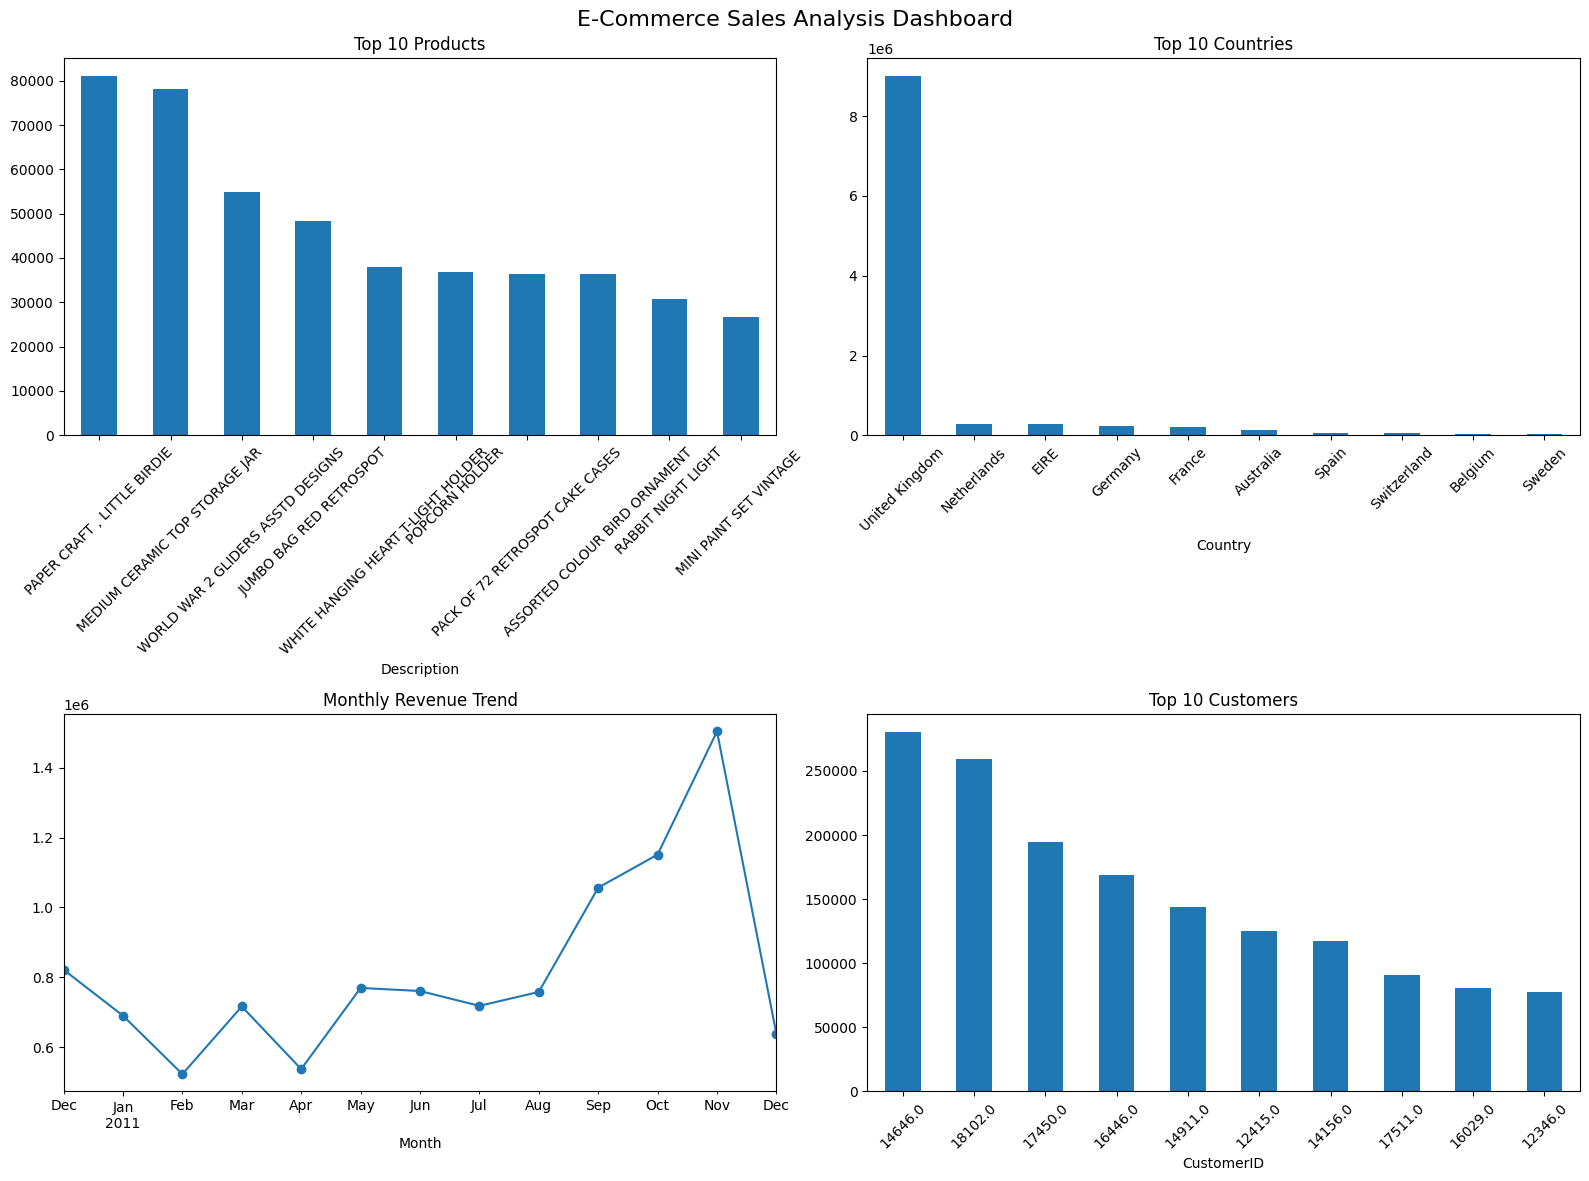

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Top 10 Products
top_products.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Top 10 Products")
axes[0, 0].tick_params(axis="x", rotation=45)

# 2. Top 10 Countries
country_sales.plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Countries")
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Monthly Revenue
monthly_sales.plot(kind="line", marker="o", ax=axes[1, 0])
axes[1, 0].set_title("Monthly Revenue Trend")

# 4. Top 10 Customers
top_customers.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Top 10 Customers")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.suptitle("E-Commerce Sales Analysis Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
print("========== E-COMMERCE SALES ANALYSIS REPORT ==========")

print("1. Total Revenue (£):", round(sales_df["Revenue"].sum(), 2))

print("2. Total Orders:", sales_df["InvoiceNo"].nunique())

print("3. Total Products:", sales_df["Description"].nunique())

print("4. Total Customers:", sales_df["CustomerID"].nunique())

print("5. Top Selling Product:")
print(top_products.index[0])

print("6. Highest Revenue Country:")
print(country_sales.idxmax())

print("7. Best Revenue Month:")
print(monthly_sales.idxmax())

print("======================================================")

========== E-COMMERCE SALES ANALYSIS REPORT ==========
1. Total Revenue (£): 10642110.8
2. Total Orders: 19960
3. Total Products: 4026
4. Total Customers: 4338
5. Top Selling Product:
PAPER CRAFT , LITTLE BIRDIE
6. Highest Revenue Country:
United Kingdom
7. Best Revenue Month:
2011-11
